<a href="https://colab.research.google.com/github/aayushttimalsina/pytorch/blob/main/01_pytorch_workflow_learnt_training_regression_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
from torch import nn
import matplotlib.pyplot as plt

#check putorch version
torch.__version__


'2.11.0+cu130'

###here we create the parameters/ data of random numbers and X is tensor here



---



In [ ]:
 # create known parameters
weight = 0.7
bias = 0.3

#create
start = 0
end = 1
step = 0.02
X = torch.arange(start, end, step).unsqueeze(1)
y = weight* X + bias

X[: 10], y[: 10], X.shape



(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]),
 torch.Size([50, 1]))

In [ ]:
len(X), len(y)

(50, 50)

###here we split the data that was previously generated above

In [ ]:
# Spilitting the data into training and testing

train_split = int(0.8 * len(X))

X_train, y_train =X[ : train_split], y[ : train_split]
X_test, y_test = X[train_split : ], y[train_split : ]
len(X_train), len(y_train), len(X_test), len(y_test)



(40, 40, 10, 10)

In [ ]:
X_train, y_train

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800],
         [0.2000],
         [0.2200],
         [0.2400],
         [0.2600],
         [0.2800],
         [0.3000],
         [0.3200],
         [0.3400],
         [0.3600],
         [0.3800],
         [0.4000],
         [0.4200],
         [0.4400],
         [0.4600],
         [0.4800],
         [0.5000],
         [0.5200],
         [0.5400],
         [0.5600],
         [0.5800],
         [0.6000],
         [0.6200],
         [0.6400],
         [0.6600],
         [0.6800],
         [0.7000],
         [0.7200],
         [0.7400],
         [0.7600],
         [0.7800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260],
         [0.4400],
         [0.4540],
         [

## how can we visualize the data


In [ ]:
def plot_predictions(train_data=X, train_labels=y, test_data=X_test, test_labels=y_test, predictions=None):
    """
    Plots training data, test data and compares predictions.
    """
    plt.figure(figsize=(5, 4))

    #plotting the data in blue

    plt.scatter(train_data, train_labels, c="b", s=4, label="training data")
    plt.scatter(test_data, test_labels, c="g", s=4, label="test data")

    #are there predictions

    if predictions is not None:
        plt.scatter(test_data, predictions, c="r", s=4, label="predictions")

    plt.legend(prop={"size": 14})

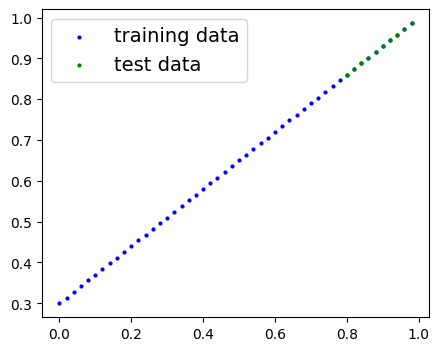

In [ ]:
plot_predictions();


##first pytorch linear model

In [ ]:
# create a linear regression model class

class LinearRegressionModel(nn.Module):
  def __init__(self):
     super().__init__()
     # Error was here: nn.parameter should be nn.Parameter
     self.weights = nn.Parameter(torch.randn(1, requires_grad=True, dtype=torch.float))
     self.bias = nn.Parameter(torch.randn(1, requires_grad=True, dtype=torch.float))

  # The forward method was incorrectly defined outside the class or with wrong indentation
  def forward(self, x: torch.Tensor) -> torch.Tensor: # <- "x" is the input data
    return self.weights * x + self.bias  #this is linear regression formula


In [ ]:

#create a manual seed
torch.manual_seed(42)


# Creating an instance of the model
model_0 = LinearRegressionModel()

# Listing the parameters of the model
list(model_0.parameters())

NameError: name 'torch' is not defined

In [ ]:
### pytorch essentials

# torch.nn - comntains all of the buildings for computational graph
# torch.parameter - what the model should learn from
#torch.mm.Module  - if u subclass it you have to use forwrd() too
# def forward # use to forward computate

In [ ]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [ ]:
weight, bias

(0.7, 0.3)

In [ ]:
### making predictions using "torch.inference_mode()"

## to check our models predictive power, lets see how well it predicts "Y_test " on "x_test"
# when we going to pass data through our model, its going to run it through the forward() method

In [ ]:
X_test, y_test

(tensor([[0.8000],
         [0.8200],
         [0.8400],
         [0.8600],
         [0.8800],
         [0.9000],
         [0.9200],
         [0.9400],
         [0.9600],
         [0.9800]]),
 tensor([[0.8600],
         [0.8740],
         [0.8880],
         [0.9020],
         [0.9160],
         [0.9300],
         [0.9440],
         [0.9580],
         [0.9720],
         [0.9860]]))

In [ ]:
## make predictions with the model

with torch.inference_mode():
  y_preds = model_0(X_test)
y_preds


tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

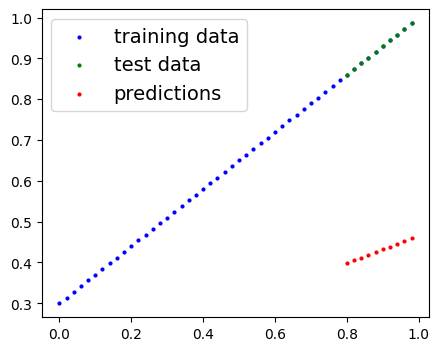

In [ ]:
plot_predictions(predictions=y_preds)

## the whole idea of training is for model to move from some unknown parameters to some known parameters one way to measure how wrong predictions are we use loss function    

*note : loss function may also be called cost function or criterian in different ares. for our case, we are going to refer to it as a loss function


loss function : a function to measure how wrong are you model predictions are to the ideal oputput

*optimizer : take into the loss of the model and adjust the models parameters to improve the los=s function

and in pytorch we need
+ training loop
+ testing loop

In [ ]:
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [ ]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [ ]:
## Setup the loss function
loss_fn = nn.L1Loss()

##Setup the optimizer(stochastic gradient descent)

optimizer = torch.optim.SGD(model_0.parameters(), lr=0.01, momentum=0.9)

##building a training and testing loop

a couple of things we need in the training loop:

+ loop through the data
+ forward pass(that involves date moving through our model)
+ calculate the loss(compare forward pass prediction to ground truth label)
+ optimizer zero grad
+ loss backward (moves backward to teh network to calculate the gardient pof the each of the parameter of our model with respect to the loss{back propagation} )
+ optimizer step : to minimize the loss

In [ ]:
torch.manual_seed(42)

### an epoch is one loop through the data
epochs = 200
epoch_count =[]
loss_values = []
test_loss_values = []
##training
# 0. loop through the data

for epoch in range(epochs):
  # set the model to training mode
  model_0.train()# train mode in pytorch sets all parameters that requires gradient descent
  # 1. forward pass
  y_pred = model_0(X_train)

  # 2. C alculate the loss
  loss = loss_fn(y_pred, y_train)
  #print(f" Loss : {loss} ")

  # 3. optimizer zero grad
  optimizer.zero_grad()

  # 4. Perform backpropagation on the loss with respect to the parameters to the mode
  loss.backward()

  # 5. Step the optimizer(perform gradient descent)
  optimizer.step() #by default how the optimizer change will accumulate through the loop so we have to zero them above in step e for the next iteration

  model_0.eval()


  ###testing loop inside the training loop
  model_0.eval() # turns of the gradient tracking with torch.inference_mode():   test_pred = model_0(X_test)   test_loss = loss_fn(test_pred, y_test) if epoch % 10 == 0 :  print(f" Epoch : {epoch} | Loss : {loss} | Test loss : {test_loss}") i wnat this to print outside the training loop

  with torch.inference_mode():
    test_pred = model_0(X_test)
    test_loss = loss_fn(test_pred, y_test)
  if epoch % 10 == 0:
    epoch_count.append(epoch)
    loss_values.append(loss)
    test_loss_values.append(test_loss)
    print(f" Epoch : {epoch} | Loss : {loss} | Test loss : {test_loss}")

 Epoch : 0 | Loss : 0.31288138031959534 | Test loss : 0.48106518387794495
 Epoch : 10 | Loss : 0.10313145816326141 | Test loss : 0.026505161076784134
 Epoch : 20 | Loss : 0.06960087269544601 | Test loss : 0.1943041831254959
 Epoch : 30 | Loss : 0.04656733572483063 | Test loss : 0.027078520506620407
 Epoch : 40 | Loss : 0.021285563707351685 | Test loss : 0.001966828014701605
 Epoch : 50 | Loss : 0.015717655420303345 | Test loss : 0.0101406155154109
 Epoch : 60 | Loss : 0.009445277974009514 | Test loss : 0.02402856945991516
 Epoch : 70 | Loss : 0.007414478808641434 | Test loss : 0.007351130247116089
 Epoch : 80 | Loss : 0.0018297977512702346 | Test loss : 0.009309673681855202
 Epoch : 90 | Loss : 0.004054517950862646 | Test loss : 0.004079228732734919
 Epoch : 100 | Loss : 0.005789133254438639 | Test loss : 0.011751467362046242
 Epoch : 110 | Loss : 0.004738811403512955 | Test loss : 0.004858058877289295
 Epoch : 120 | Loss : 0.0055055171251297 | Test loss : 0.010634839534759521
 Epoch :

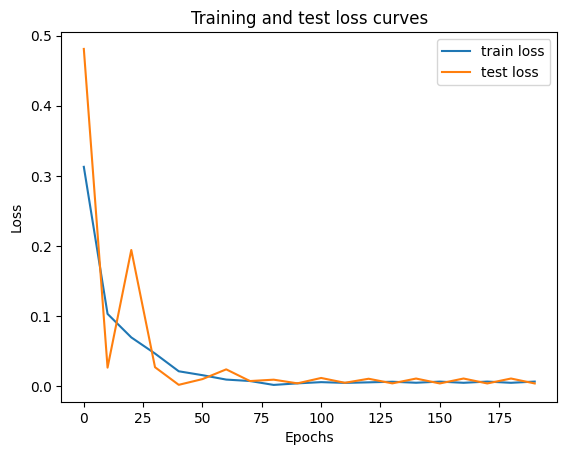

In [ ]:
#plot the loss curve
import numpy as np
plt.plot(epoch_count, np.array(torch.tensor(loss_values).numpy()), label = "train loss")
plt.plot(epoch_count, test_loss_values , label = "test loss")
plt.title("Training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend();

In [ ]:
# Testing code — outside the training loop
model_0.eval()

with torch.inference_mode():
    test_pred = model_0(X_test)
    test_loss = loss_fn(test_pred, y_test)

print(f"Loss: {loss} | Test loss: {test_loss}")
print(f"Epoch: {epoch + 1} | Loss: {loss} | Test loss: {test_loss}")

Loss: 0.005492871161550283 | Test loss: 0.003180819796398282
Epoch: 200 | Loss: 0.005492871161550283 | Test loss: 0.003180819796398282


In [ ]:
with torch.inference_mode():
  y_preds_new = model_0(X_test)



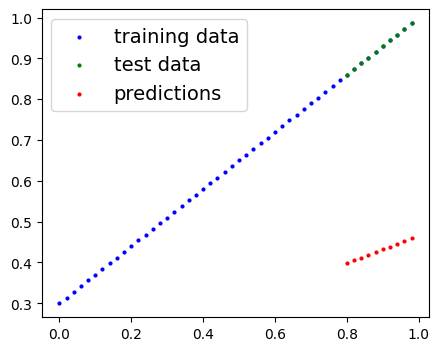

In [ ]:
plot_predictions(predictions = y_preds)

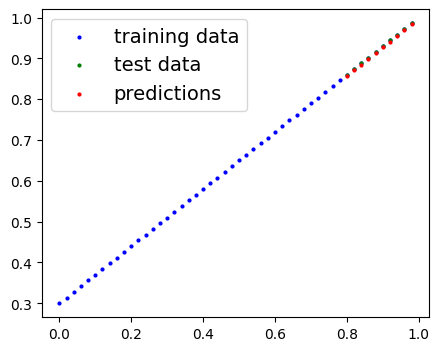

In [ ]:
plot_predictions(predictions = y_preds_new)

## saving our model in pytorch

there are three different methods to save and load models on pytorch.

1. torch.save() - allows you save a pytorch object in python pickle format
2. torch.load() - allows you to load model
3. torch.nn.module.load_state_dict()  -  this allows too load a modle saved state dictionary

In [ ]:
##saving pytorch model
from pathlib import Path

# create models directory

MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

#create model svae path
MODEL_NAME = "01_pytorch_workflow_model_0.pth"
MODEL_SAVE_PATH = MODEL_PATH/MODEL_NAME


# save the model

print(f" Saving model to {MODEL_SAVE_PATH}")
torch.save(obj=model_0.state_dict(), f=MODEL_SAVE_PATH)



 Saving model to models/01_pytorch_workflow_model_0.pth


In [ ]:
!ls -l models

total 4
-rw-r--r-- 1 root root 2117 Oct 13 16:38 01_pytorch_workflow_model_0.pth


In [ ]:
#create a  new instance
loaded_model_0 = LinearRegressionModel()

#loading saved model state_dict
loaded_model_0.load_state_dict(torch.load(MODEL_SAVE_PATH))
loaded_model_0

LinearRegressionModel()

In [ ]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.7034])), ('bias', tensor([0.2938]))])

In [ ]:
loaded_model_0

LinearRegressionModel()

In [ ]:
### make some predictions

loaded_model_0.eval()

with torch.inference_mode():
  loaded_model_preds = loaded_model_0(X_test)

loaded_model_preds

tensor([[0.8565],
        [0.8706],
        [0.8847],
        [0.8987],
        [0.9128],
        [0.9269],
        [0.9409],
        [0.9550],
        [0.9691],
        [0.9831]])

In [ ]:
y_preds == loaded_model_preds

tensor([[False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False],
        [False]])

In [ ]:
#create a linear model by subclassing nn.module
class LinearRegressionModelV2(nn.Module):
  def __init__(self):
     super().__init__()
     #use nn.linear() for creating the model parameters / also called linear transform / dense layer

     self.linear_layer = nn.Linear(in_features=1,
                                   out_features=1)

  def forward(self, x: torch.Tensor) -> torch.tensor:
    return self.linear_layer(x)


  #set manual seed

torch.manual_seed(42)

model_1 = LinearRegressionModelV2()

model_1, model_1.state_dict()


(LinearRegressionModelV2(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]))

In [ ]:
class LinearRegressionModelV2(nn.Module):
  def __init__(self):
     super().__init__()

     self.layer_1 = nn.Linear(in_features=1,
                                   out_features=1)
  def forward(se x: torch.Tensor) -> torch.tensor:
    return self.layer_1(x)lf,

torch.manual_seed(42)
model_1 = LinearRegressionModelV2()
model_1, model_1.state_dict()


(LinearRegressionModelV2(
   (layer_1): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('layer_1.weight', tensor([[0.7645]])),
              ('layer_1.bias', tensor([0.8300]))]))

In [ ]:
#model to use the target device

'cuda'

'cuda'

In [ ]:
next(model_1.parameters()).device

device(type='cpu')

In [ ]:

device = "cuda" if torch.cuda.is_available() else "cpu"


model_1.to(device)
next(model_1.parameters()).device

device(type='cuda', index=0)